In [1]:
# 1. Pre-process Dataset

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

In [3]:
# load dataset
df = pd.read_csv("uber.csv");
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
# handling missing values
print(df.isnull().sum())
df.dropna(inplace=True)
print("\nShape after removing missing values: ", df.shape)

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Shape after removing missing values:  (199999, 9)


In [5]:
# handling duplicates 
print("Duplicate records: ", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("\nShape after removing duplicates:", df.shape)

Duplicate records:  0

Shape after removing duplicates: (199999, 9)


In [6]:
# remove unnecessary columns
df.drop( columns=['Unnamed: 0', 'key'], errors='ignore', inplace=True )

print(df.columns)

Index(['fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'passenger_count'],
      dtype='str')


In [7]:
# convert pickup datetime
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

df.dropna(subset=['pickup_datetime'],inplace=True)

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

df.drop(columns=['pickup_datetime'], inplace=True)
    

In [8]:
# remove invalid values
df = df[(df['fare_amount'] > 0) & (df['passenger_count'] > 0) ]

In [9]:
# verify cleaned dataset
print("\nFinal shape: ",df.shape)
print("\nMissing values: \n",df.isnull().sum())

df.head()


Final shape:  (199269, 10)

Missing values: 
 fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
month                0
year                 0
dtype: int64


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014


In [10]:
# 2. IDENTIFY OUTLIERS

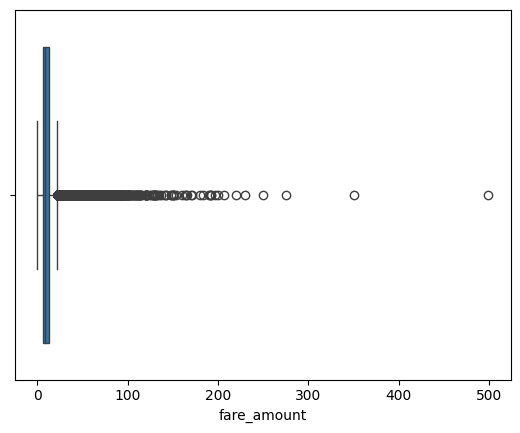

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# visualize outliers
sns.boxplot(x=df['fare_amount'])
plt.show()

In [12]:
#identify outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3-Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit : ", lower)
print("Upper limit : ", upper)

Lower limit :  -3.75
Upper limit :  22.25


In [13]:
# remove outliers
df = df[ (df['fare_amount'] >= lower) & (df['fare_amount'] <= upper) ]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (182148, 10)


In [14]:
# 3. Check the correlation

In [15]:
# calculate correlation 
corr = df.corr(numeric_only=True)
print(corr)

                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000125         0.002826   
pickup_longitude      0.000125          1.000000        -0.811435   
pickup_latitude       0.002826         -0.811435         1.000000   
dropoff_longitude    -0.002534          0.835878        -0.766797   
dropoff_latitude      0.000715         -0.850520         0.683972   
passenger_count       0.011995         -0.000582        -0.001742   
hour                 -0.013304          0.003668        -0.004779   
day                   0.007128          0.003436        -0.006933   
month                 0.026188         -0.003842         0.004069   
year                  0.135630          0.009803        -0.009843   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.002534          0.000715         0.011995   
pickup_longitude            0.835878         -0.850520        -0.000582   
pickup_latitude

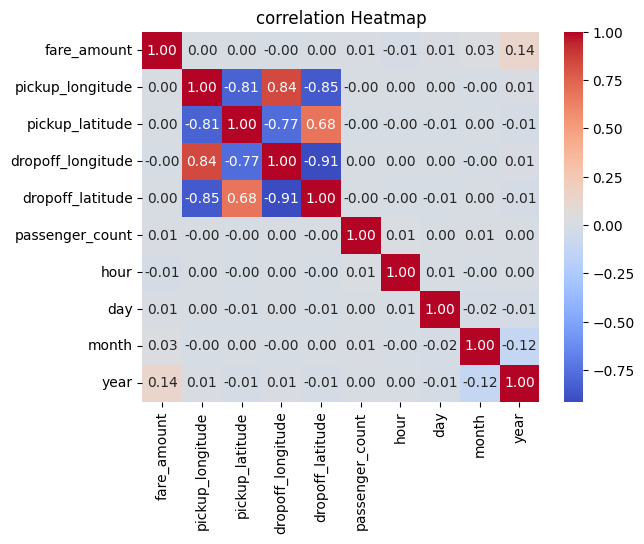

In [16]:
# check correlation using heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("correlation Heatmap")
plt.show()

In [17]:
# check the correlation with fare
print(corr['fare_amount'])

fare_amount          1.000000
pickup_longitude     0.000125
pickup_latitude      0.002826
dropoff_longitude   -0.002534
dropoff_latitude     0.000715
passenger_count      0.011995
hour                -0.013304
day                  0.007128
month                0.026188
year                 0.135630
Name: fare_amount, dtype: float64


In [18]:
# 4. Implement Linear Regression and Random Forest Regression

In [19]:
# separate features and target
x = df.drop('fare_amount', axis=1)
y = df['fare_amount']

In [20]:
# split the dataset
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
) 

In [21]:
# implement linear regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

In [22]:
# Implement Random Forest Regression
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators = 100, random_state=42)
rf.fit(x_train, y_train)

y_pred_rf = rf.predict(x_test)

In [23]:
# 5. Evaluate the models and compare their respective scores like R2, RMSE, etc.

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Linear Regression")
mae = mean_absolute_error(y_test, y_pred) #average of absolute error |y - y^|
print("Mean Absolute Error = ", mae)
mse = mean_squared_error(y_test, y_pred) #(|y-y^|)^2
print("Mean Squared Error = ",mse)
rmse = np.sqrt(mse) #root mean squared error
print("Root Mean Squared Error = ", rmse)
r2 = r2_score(y_test, y_pred) #measures how well model fits data 1.0 <- perfect prediction, 0.0 <- useless model, <0 <- worse than guessing
print("R2 Score", r2)

Linear Regression
Mean Absolute Error =  3.2428308225757787
Mean Squared Error =  16.68018652181982
Root Mean Squared Error =  4.084138406300626
R2 Score 0.021851684878975708


In [25]:
print("Random Forest")
mae = mean_absolute_error(y_test, y_pred_rf) #average of absolute error |y - y^|
print("Mean Absolute Error = ", mae)
mse = mean_squared_error(y_test, y_pred_rf) #(|y-y^|)^2
print("Mean Squared Error = ",mse)
rmse = np.sqrt(mse) #root mean squared error
print("Root Mean Squared Error = ", rmse)
r2 = r2_score(y_test, y_pred_rf) #measures how well model fits data 1.0 <- perfect prediction, 0.0 <- useless model, <0 <- worse than guessing
print("R2 Score", r2)

Random Forest
Mean Absolute Error =  1.393844431786989
Mean Squared Error =  4.170246501315046
Root Mean Squared Error =  2.0421181408809446
R2 Score 0.7554512005267658


In [26]:
# compare both models
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE' : [mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test,y_pred_rf)],
    'RMSE' : [mean_squared_error(y_test, y_pred), mean_squared_error(y_test, y_pred_rf)],
    'R2 Score' : [r2_score(y_test, y_pred), r2_score(y_test, y_pred_rf)]
})

print(results)

               Model       MAE       RMSE  R2 Score
0  Linear Regression  3.242831  16.680187  0.021852
1      Random Forest  1.393844   4.170247  0.755451
